Let's create some personalized architectures.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import MessagePassing, global_mean_pool, global_add_pool, global_max_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from collections import Counter
import matplotlib.pyplot as plt
import random
from sklearn.model_selection import train_test_split
import json
import random
import numpy as np

print("PyTorch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")


. @Oxford/Hilary/Geometric deep learning/Mini-project-code/torch-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.10.0
Device: cpu


In [2]:
def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]

raw = load_jsonl("../data/cayley_dict_unique_100.jsonl")
raw += load_jsonl("../data/cayley_dict_unique_51_200.jsonl")[791:]
raw += load_jsonl("../data/cayley_ten_gens_each_50.jsonl")
raw += load_jsonl("../data/cayley_dict_five_gens_each_51_150.jsonl")

print(f"Loaded {len(raw)} graphs")
print("Example keys:", list(raw[0].keys()))

Loaded 26680 graphs
Example keys: ['edge_index', 'edge_label', 'num_generators', 'num_vertices', 'num_edges', 'is_abelian', 'group_id']


In [3]:
def build_pyg_dataset(cayley_dicts):
    """
    Convert raw dicts → list of PyG Data objects.
    Node features x:    all-ones vector (shape: [num_nodes, 1])
                        We start simple — no structural features yet.
    Edge features:      one-hot encoding of which generator produced the edge
                        (shape: [num_edges, max_num_generators])
    Label y:            is_abelian (0 or 1)
    """
    max_gens = max(d["num_generators"] for d in cayley_dicts)
    dataset = []
    for d in cayley_dicts:
        edge_index = torch.tensor(d["edge_index"], dtype=torch.long).t().contiguous()
        # One-hot encode each edge by which generator it came from
        num_edges  = d["num_edges"]
        edge_attr  = torch.zeros(num_edges, max_gens)
        gen_labels = d["edge_label"][:d["num_generators"]]   # unique label values
        for i, lbl in enumerate(d["edge_label"]):
            edge_attr[i, gen_labels.index(lbl)] = 1.0
        x = torch.randn(d["num_vertices"], 8)   # random positional encoding, dim=8
        #x = torch.ones(d["num_vertices"], 1)                 # trivial node features
        y = torch.tensor([d["is_abelian"]], dtype=torch.long)
        dataset.append(Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y))

    return dataset, max_gens


dataset, edge_dim = build_pyg_dataset(raw)


In [4]:
print(f"edge_dim (max generators across all graphs): {edge_dim}")
print("num_graphs:", len(dataset))
print("num_abelian_graphs:", len([d for d in dataset if int(d.y) == 1]) )
print("num_non_abelian_graphs:", len([d for d in dataset if int(d.y) == 0]) )

edge_dim (max generators across all graphs): 7
num_graphs: 26680
num_abelian_graphs: 2206
num_non_abelian_graphs: 24474


In [5]:
def see_distribution(list1, list2, label1, label2, numberof = 'node'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(list1,  bins=30, alpha=0.7, label=label1,     color='steelblue')
    axes[0].hist(list2, bins=30, alpha=0.7, label=label2, color='salmon')
    axes[0].set_xlabel(numberof)
    axes[0].set_ylabel('Count')
    axes[0].legend()

    axes[1].hist(list1,  bins=30, alpha=0.7, label=label1,     color='steelblue', density=True)
    axes[1].hist(list2, bins=30, alpha=0.7, label=label2, color='salmon',    density=True)
    axes[1].set_xlabel(numberof)
    axes[1].set_ylabel('Density')
    axes[1].set_title('Normalised')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

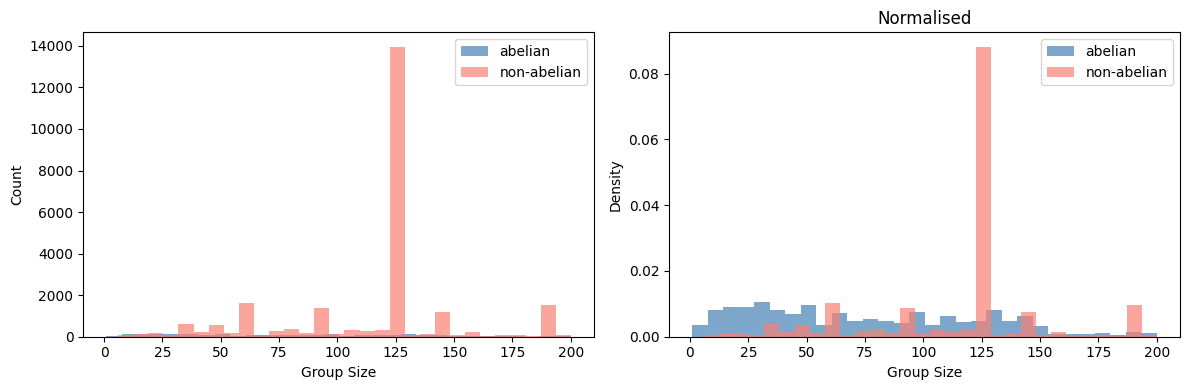

In [6]:
ab_nodes = [d.x.shape[0] for d in [e for e in dataset if int(e.y) == 1]]
nab_nodes = [d.x.shape[0] for d in [e for e in dataset if int(e.y) == 0]]
see_distribution(ab_nodes,nab_nodes , 'abelian', 'non-abelian', numberof = 'Group Size')

Let's make a Balanced set of abelian and non-abelian graphs. There are 26680 graphs, and 2206 are abelian, and the number of non-abelian-graphs are 24474, which is a lot. 

In [7]:
def make_balanced_dataset(dataset, seed=1):
    abelian     = [d for d in dataset if int(d.y) == 1]
    non_abelian = [d for d in dataset if int(d.y) == 0]

    rng = random.Random(seed)
    sampled_non_abelian = rng.sample(non_abelian, len(abelian))

    balanced = abelian + sampled_non_abelian
    rng.shuffle(balanced)
    return balanced

balanced_dataset = make_balanced_dataset(dataset)

In [8]:
len(balanced_dataset)

4412

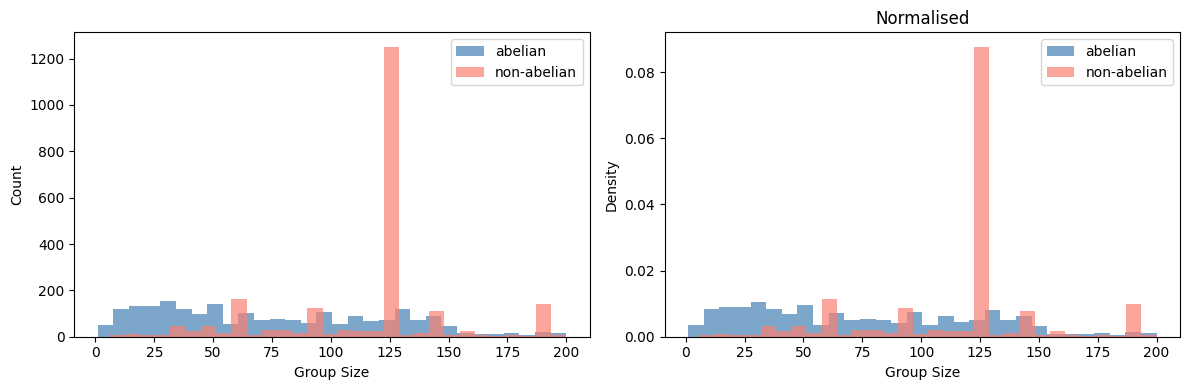

In [9]:
ab_nodes_balanced = [d.x.shape[0] for d in [d for d in balanced_dataset if int(d.y) == 1]]
nab_nodes_balanced = [d.x.shape[0] for d in [d for d in balanced_dataset if int(d.y) == 0]]
see_distribution(ab_nodes_balanced, nab_nodes_balanced, 'abelian', 'non-abelian', numberof = 'Group Size')
#all_sizes  = sorted(set(ab_nodes) | set(nab_nodes))



In [10]:
def stratified_split(dataset, seed=42):
    """70/15/15 split, stratified by label so both splits have similar class balance."""
    labels = [int(d.y) for d in dataset]
    idx    = list(range(len(dataset)))

    train_idx, temp_idx = train_test_split(idx, test_size=0.30, random_state=seed, stratify=labels)
    temp_labels = [labels[i] for i in temp_idx]
    val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=seed, stratify=temp_labels)

    return ([dataset[i] for i in train_idx],
            [dataset[i] for i in val_idx],
            [dataset[i] for i in test_idx])

We define a matrix of size $M$ where $M_{ij} = 1$ if we include the level $i$ #maybe it is some polynomial feature or something. I don't know. It might be useful when seeing whether the algebra is finitely generated but for now it doesn't seem very useful. That should be interesting. the algebra of message passing architectures or morphism based things? Hmm.

In [11]:
class LocalIn(MessagePassing):
    def __init__(self, in_channels, out_channels, aggr = 'add', act = F.relu):
        super().__init__(aggr = aggr, flow= 'source_to_target')
        self.W_self = nn.Linear(in_channels, out_channels)
        self.W_neigh = nn.Linear(in_channels, out_channels) 
        self.act = act

    def forward(self, x, edge_index):
        # self.propagate will call message() then aggregate(), then pass result to update()
        # We pass x so it's available inside message() as x_j (source) and x_i (target)
        return self.propagate(edge_index, x=x)
    
    def message(self, x_j):
        return self.W_neigh(x_j)
    
    def update(self, aggr_out, x):
        # aggr_out: aggregated neighbour messages, shape [num_nodes, out_channels]
        # x:        original node features,         shape [num_nodes, in_channels]
        return self.act(self.W_self(x) + aggr_out)
    
class LocalOut(MessagePassing):
    def __init__(self, in_channels, out_channels, aggr = 'add', act =F.relu):
        super().__init__(aggr = aggr, flow = 'target_to_source')
        self.W_self = nn.Linear(in_channels, out_channels)
        self.W_neigh = nn.Linear(in_channels, out_channels) 
        self.act = act
    def forward(self, x, edge_index):
        #x: [num_nodes, in_channels]. This consists of the node embeddings.
        #edge_index: [2, num_edges] (row 0 = source, row 1 = target)
        return self.propagate(edge_index, x = x)
    
    def message(self, x_j):
        return x_j
    
    def update(self, aggr_out, x):
        return self.act(self.W_self(x) + aggr_out)

class LocalInOut(MessagePassing):
    def __init__(self, in_channels, out_channels, aggr='add', act=F.relu):
        super().__init__(aggr=aggr, flow='source_to_target')
        self.W_self = nn.Linear(in_channels, out_channels)
        self.W_neigh_in  = nn.Linear(in_channels, out_channels)  # messages from sources
        self.W_neigh_out = nn.Linear(in_channels, out_channels)  # messages from targets
        self.act = act

    def forward(self, x, edge_index):
        # source -> target  (node receives from its sources)
        agg_in  = self.propagate(edge_index, x=x, direction='in')
        # reverse: target -> source  (node receives from its targets)
        agg_out = self.propagate(edge_index.flip(0), x=x, direction='out')

        return self.act(self.W_self(x) + agg_in + agg_out)

    def message(self, x_j, direction):
        if direction == 'in':
            return self.W_neigh_in(x_j)
        else:
            return self.W_neigh_out(x_j)
    

    
#let's build an attention class and see whether that performs poorly (overfitting?) 

Now we add "edge-aware" message passing layers. This should work better for Abelian groups.

In [12]:
class LocalInEdge(MessagePassing):
    def __init__(self, in_channels, out_channels, edge_channels, aggr="add", act=F.relu,):
        super().__init__(aggr=aggr, flow="source_to_target") #the aggregagtion is specified here.
        #Message
        self.W_neigh = nn.Linear(in_channels, out_channels)
        self.W_edge = nn.Linear(edge_channels, out_channels)
        #node update
        self.W_self = nn.Linear(in_channels, out_channels)
        self.act = act

    def forward(self, x, edge_index, edge_attr):
        return self.propagate(edge_index, x=x, edge_attr =edge_attr)

    def message(self, x_j, edge_attr):
        msg = self.W_neigh(x_j) + self.W_edge(edge_attr)
        return msg

    def update(self, aggr_out, x):
        return self.act(self.W_self(x) + aggr_out)

Now we can create a simple message-passing GNN to see how it works. We can customize it to see the number of different layers etc. A good test would be to see its prediction score when the input is a group of size 128 and how many it correctly classifies out of them. It should commutativity structure regardless. Maybe not -- maybe the things which can algorithmicaly be determined can be "combined".

In [13]:
POOLING = {
    'mean': global_mean_pool,
    'sum':  global_add_pool,
    'max':  global_max_pool,
}

class CayleyGNN(nn.Module):
    """
    edge_dim : int
        Dimension of edge features (needed for 'edge_aware' layer).
    num_classes : int
        Number of output classes (2 for abelian/non-abelian).
    pooling : str
        How to aggregate node features into a graph vector: 'mean' | 'sum' | 'max'
    aggr : str
        Aggregation inside each MP layer: 'add' | 'mean' | 'max'
    """

    def __init__(self, layer_type  = 'LocalInEdge',
                 num_layers  = 3,
                 hidden_dim  = 64,
                 edge_dim    = 7,
                 num_classes = 2,
                 pooling     = 'mean',
                 aggr        = 'add'):
        super().__init__()
        self.layer_type = layer_type
        self.pool_fn    = POOLING[pooling]
        self.convs = nn.ModuleList()
        for i in range(num_layers):
            in_dim = 8 if i == 0 else hidden_dim    # first layer: input is 1-dim. Every node has the constant label 1. 
            if layer_type == 'LocalIn':
                self.convs.append(LocalIn(in_dim, hidden_dim, aggr=aggr))
            elif layer_type == 'LocalOut':
                self.convs.append(LocalOut(in_dim, hidden_dim, aggr=aggr))
            elif layer_type == 'LocalInOut':
                self.convs.append(LocalInOut(in_dim, hidden_dim, aggr = aggr))
            elif layer_type == 'LocalInEdge':
                self.convs.append(LocalInEdge(in_dim, hidden_dim, edge_dim, aggr = aggr))
            else:
                raise ValueError(f"Unknown layer_type: {layer_type}")
    
        self.classifier = nn.Linear(hidden_dim, num_classes) #the final layer is a linear layer. This is applied after pooling!

    def forward(self, x, edge_index, edge_attr, batch):
        for conv in self.convs:
            if self.layer_type == 'LocalInEdge':
                x = conv(x, edge_index, edge_attr)
            else:
                x = conv(x, edge_index)

        x = self.pool_fn(x, batch)     # [num_graphs, hidden_dim]. Here we are taking the average of the node embeddings.
        return self.classifier(x)      # [num_graphs, num_classes] #returns logits afterwards we measure cross-entropy loss.


#model = CayleyGNN(layer_type='LocalIn', num_layers=2, hidden_dim=10, edge_dim=edge_dim)
#loader = DataLoader(balanced_dataset, batch_size=4, shuffle = True) #splits the dataset into batches.
#batch  = next(iter(loader))
#out    = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
#print("Model output shape:", out.shape)   # [4, 2]  — logits for 4 graphs, 2 classes
#print(model)

In [14]:
def train_one_epoch(model, loader, optimizer, device):
    model.train() #model in training mode. 
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad() #in each batch, we want to start fresh.
        out  = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = F.cross_entropy(out, batch.y) #computes the loss between output and correct answer
        loss.backward() #computes the gradients
        optimizer.step() #updates the weights by learning step (gradient descent)
        total_loss += loss.item()
    return total_loss

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    correct, total = 0, 0
    for batch in loader:
        batch = batch.to(device)
        out   = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        pred  = out.argmax(dim=1)
        correct += (pred == batch.y).sum().item()
        total   += batch.y.size(0)
    return correct / total

@torch.no_grad()
def get_all_preds(model, loader, device):
    model.eval()
    all_labels, all_preds = [], []
    for batch in loader:
        batch = batch.to(device)
        out  = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        pred = out.argmax(dim=1)
        all_labels.extend(batch.y.cpu().tolist())
        all_preds.extend(pred.cpu().tolist())
    return all_labels, all_preds


In [15]:
def run_experiment_with_plot(layer_type='LocalInEdge', num_layers=3, hidden_dim=64,edge_dim=7,
                   pooling='mean', aggr='add', epochs=30, lr=1e-3, seed=42):
    
    history = {'train_loss': [...], 'val_acc': [...], 'epochs': [...]}

    torch.manual_seed(seed)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    val_loader   = DataLoader(val_set,   batch_size=32)
    test_loader  = DataLoader(test_set,  batch_size=32)

    model = CayleyGNN(
        layer_type  = layer_type,
        num_layers  = num_layers,
        hidden_dim  = hidden_dim,
        edge_dim    = edge_dim,
        pooling     = pooling,
        aggr        = aggr,
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    print(f"Config: layer={layer_type}, layers={num_layers}, hidden={hidden_dim}, "
          f"pool={pooling}, aggr={aggr}")
    print(f"Params: {sum(p.numel() for p in model.parameters()):,}")

    history = {'train_loss': [], 'val_acc': [], 'epochs': list(range(1, epochs + 1))}

    for epoch in range(1, epochs + 1):
        loss    = train_one_epoch(model, train_loader, optimizer, device)
        val_acc = evaluate(model, val_loader, device)
        history['train_loss'].append(loss)
        history['val_acc'].append(val_acc)
        if epoch % 10 == 0:
            print(f"  Epoch {epoch:3d} | Loss {loss:.3f} | Val Acc {val_acc:.3f}")

    test_acc = evaluate(model, test_loader, device)
    print(f"  → Test Accuracy: {test_acc:.4f}")

    history['test_loader'] = test_loader
    history['device']      = device
    return model, history 

In [16]:
train_set, val_set, test_set = stratified_split(balanced_dataset)
print(f"Train: {len(train_set)}  Val: {len(val_set)}  Test: {len(test_set)}")

Train: 3088  Val: 662  Test: 662


In [17]:
# --- Experiment 1: Edge-aware layer (uses generator information) ---
model1, history1 = run_experiment_with_plot(layer_type='LocalInEdge', num_layers=5, hidden_dim=64, edge_dim = 7, pooling='mean', epochs = 30)
plot_results(model1, history1)

Config: layer=LocalInEdge, layers=5, hidden=64, pool=mean, aggr=add
Params: 37,122
  Epoch  10 | Loss 23.638 | Val Acc 0.891
  Epoch  20 | Loss 13.967 | Val Acc 0.896
  Epoch  30 | Loss 6.737 | Val Acc 0.878
  → Test Accuracy: 0.8852


NameError: name 'plot_results' is not defined

In [58]:


def run_experiment(layer_type='LocalInEdge', num_layers=3, hidden_dim=64, edge_dim = 7,
                   pooling='mean', aggr='add', epochs=30, lr=1e-3, seed=42):
    """
    Train a CayleyGNN with the given config and print results.
    Returns the trained model.
    """
    torch.manual_seed(seed)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    val_loader   = DataLoader(val_set,   batch_size=32)
    test_loader  = DataLoader(test_set,  batch_size=32)

    model = CayleyGNN(
        layer_type  = layer_type,
        num_layers  = num_layers,
        hidden_dim  = hidden_dim,
        edge_dim    = edge_dim, #THE max number of generators
        pooling     = pooling,
        aggr        = aggr,
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    print(f"Config: layer={layer_type}, layers={num_layers}, hidden={hidden_dim}, "
          f"pool={pooling}, aggr={aggr}")
    print(f"Params: {sum(p.numel() for p in model.parameters()):,}")

    for epoch in range(1, epochs + 1):
        loss = train_one_epoch(model, train_loader, optimizer, device)
        if epoch % 5 == 0:
            val_acc = evaluate(model, val_loader, device)
            print(f"  Epoch {epoch:3d} | Loss {loss:.3f} | Val Acc {val_acc:.3f}")

    test_acc = evaluate(model, test_loader, device)
    print(f"  → Test Accuracy: {test_acc:.4f}")
    return model


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import itertools

def plot_results(model, history, label='', class_names=['Non-Abelian', 'Abelian']):
    epochs      = history['epochs']
    train_loss  = history['train_loss']
    val_acc     = history['val_acc']
    test_loader = history['test_loader']
    device      = history['device']

    labels, preds = get_all_preds(model, test_loader, device)
    cm = confusion_matrix(labels, preds)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    title_prefix = f"[{label}] " if label else ""

    # --- Learning curve: loss ---
    axes[0].plot(epochs, train_loss, color='steelblue')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Training Loss')
    axes[0].set_title(f'{title_prefix}Training Loss')
    axes[0].grid(True, alpha=0.3)

    # --- Learning curve: val accuracy ---
    axes[1].plot(epochs, val_acc, color='salmon')
    axes[1].set_ylim(0, 1)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Validation Accuracy')
    axes[1].set_title(f'{title_prefix}Validation Accuracy')
    axes[1].axhline(0.5, color='grey', linestyle='--', linewidth=0.8, label='random')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # --- Confusion matrix ---
    im = axes[2].imshow(cm, interpolation='nearest', cmap='Blues')
    fig.colorbar(im, ax=axes[2])
    axes[2].set_title(f'{title_prefix}Confusion Matrix (test)')
    tick_marks = range(len(class_names))
    axes[2].set_xticks(tick_marks); axes[2].set_xticklabels(class_names)
    axes[2].set_yticks(tick_marks); axes[2].set_yticklabels(class_names)
    axes[2].set_ylabel('True label')
    axes[2].set_xlabel('Predicted label')
    thresh = cm.max() / 2
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        axes[2].text(j, i, cm[i, j], ha='center', va='center',
                     color='white' if cm[i, j] > thresh else 'black')

    plt.tight_layout()
    plt.show()
    print(classification_report(labels, preds, target_names=class_names))